*This file contain can be used for testing and visualization for the construction of the mutation graph.*

In [1]:
from mutation_graph import MutationGraph
import matplotlib.pyplot as plt
import networkx as nx

h1n1_test_graph = MutationGraph(
    inFile='raw/h1n1pdm/seasonal-flu_h1n1pdm_ha_12y.json',
    outFile='irrelevant',
    flagFile='flagged/h1n1pdm/h1n1pdm_node_flags.csv',
    rootFile='raw/h1n1pdm/seasonal-flu_h1n1pdm_ha_12y_root-sequence.json',
    gene_segments=['HA1']
    )

h3n2_test_graph = MutationGraph(
    inFile='raw/h3n2/seasonal-flu_h3n2_ha_12y.json',
    outFile='irrelevant',
    flagFile='flagged/h3n2/h3n2_node_flags.csv',
    rootFile='raw/h3n2/seasonal-flu_h3n2_ha_12y_root-sequence.json',
    gene_segments=['HA1']
    )

h1n1_test_graph.construct()
h3n2_test_graph.construct()

[('root', 'root/1', {'attributes': {'mutations': {'nuc': ['C318T', 'G625C', 'T678A', 'A911G', 'A1032G', 'T1076C', 'G1191A', 'G1423A', 'C1428T'], 'HA1': ['P83S', 'S185T', 'S203T', 'I321V'], 'HA2': ['E47K', 'S124N']}}, 'pruned_nodes': []}), ('root/1', 'root/1/1', {'attributes': {'mutations': {'nuc': ['G360A', 'A599G', 'A1406G'], 'HA1': ['D97N']}}, 'pruned_nodes': []}), ('root/1/1', 'root/1/1/1', {'attributes': {'mutations': {'nuc': ['C293T', 'T485C', 'A558C', 'G837A', 'A918G', 'A986G', 'G1178A', 'A1250G', 'G1566A', 'T1673C', 'A1742G'], 'HA1': ['K163Q', 'A256T', 'K283E'], 'HA2': ['E172K']}}, 'pruned_nodes': []}), ('root/1/1/1', 'root/1/1/1/1', {'attributes': {'mutations': {'nuc': ['T1061C']}}, 'pruned_nodes': []}), ('root/1/1/1', 'root/1/1/1/0', {'attributes': {'mutations': {'nuc': ['T31C', 'A287C', 'C389T', 'C1034T', 'T1211C', 'C1385T', 'G1577A', 'T1718C'], 'SigPep': ['I4T']}}, 'pruned_nodes': []}), ('root/1/1/1/0', 'root/1/1/1/0/1', {'attributes': {'mutations': {}}, 'pruned_nodes': []})

Let's visualize the phylogenetic trees. Nodes that will be pruned are highlighted in red.

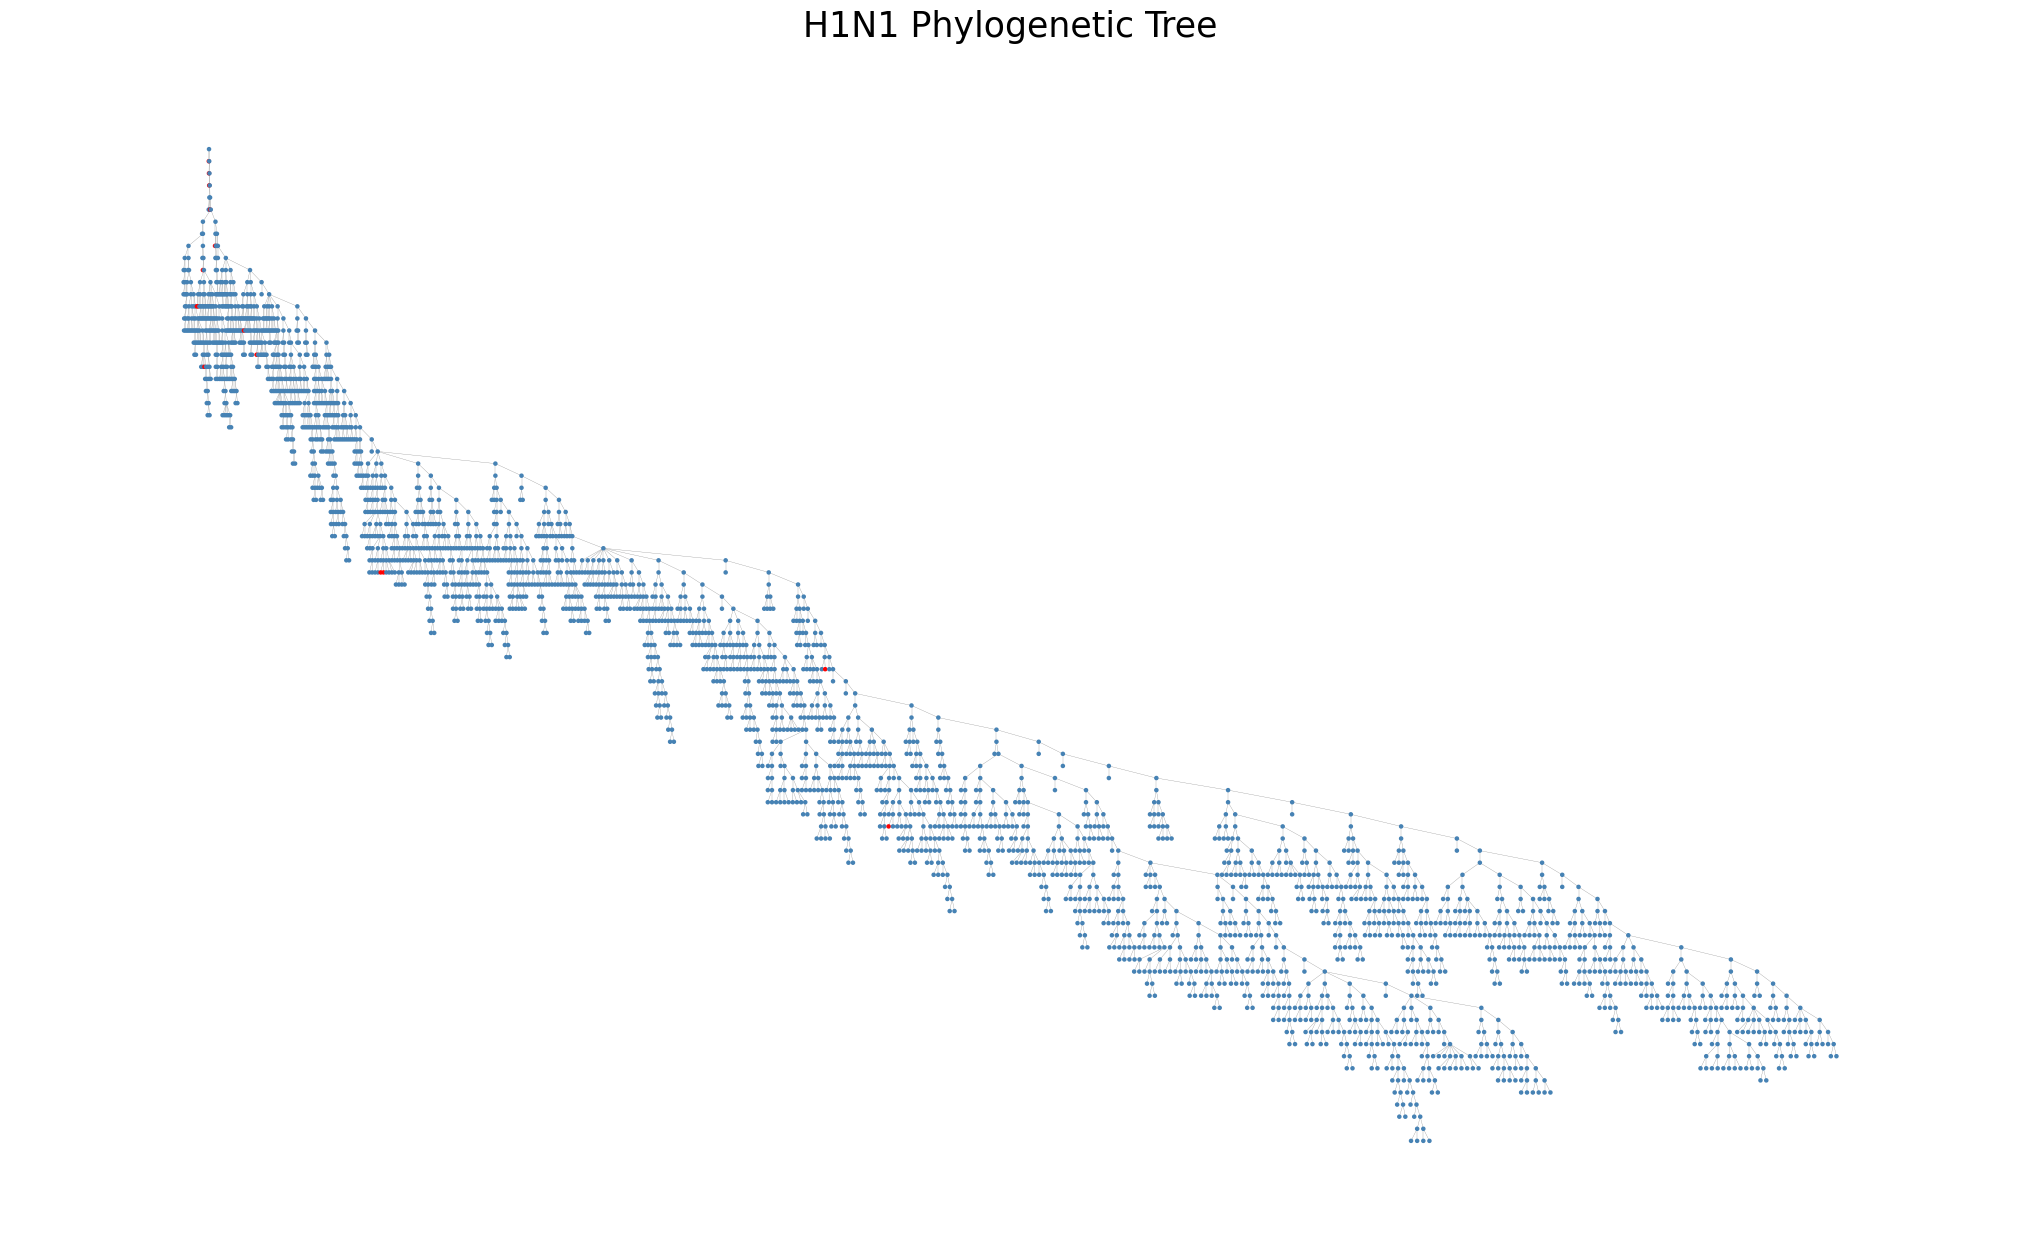

In [2]:
h1n1_phylo_tree = h1n1_test_graph.phylo_tree

nodes_to_prune = h1n1_test_graph._get_nodes_to_prune(h1n1_phylo_tree)

plt.figure(figsize=(20, 12))

pos = nx.nx_agraph.graphviz_layout(h1n1_phylo_tree, prog="dot")

node_colors = [
    "red" if node in nodes_to_prune else "steelblue"
    for node in h1n1_phylo_tree.nodes()
]

nx.draw(
    h1n1_phylo_tree,
    pos,
    with_labels=False,
    node_size=5,
    node_color=node_colors,
    edge_color="grey",
    width=0.2,
    arrows=False
)

plt.title("H1N1 Phylogenetic Tree", fontsize=25)
plt.show()

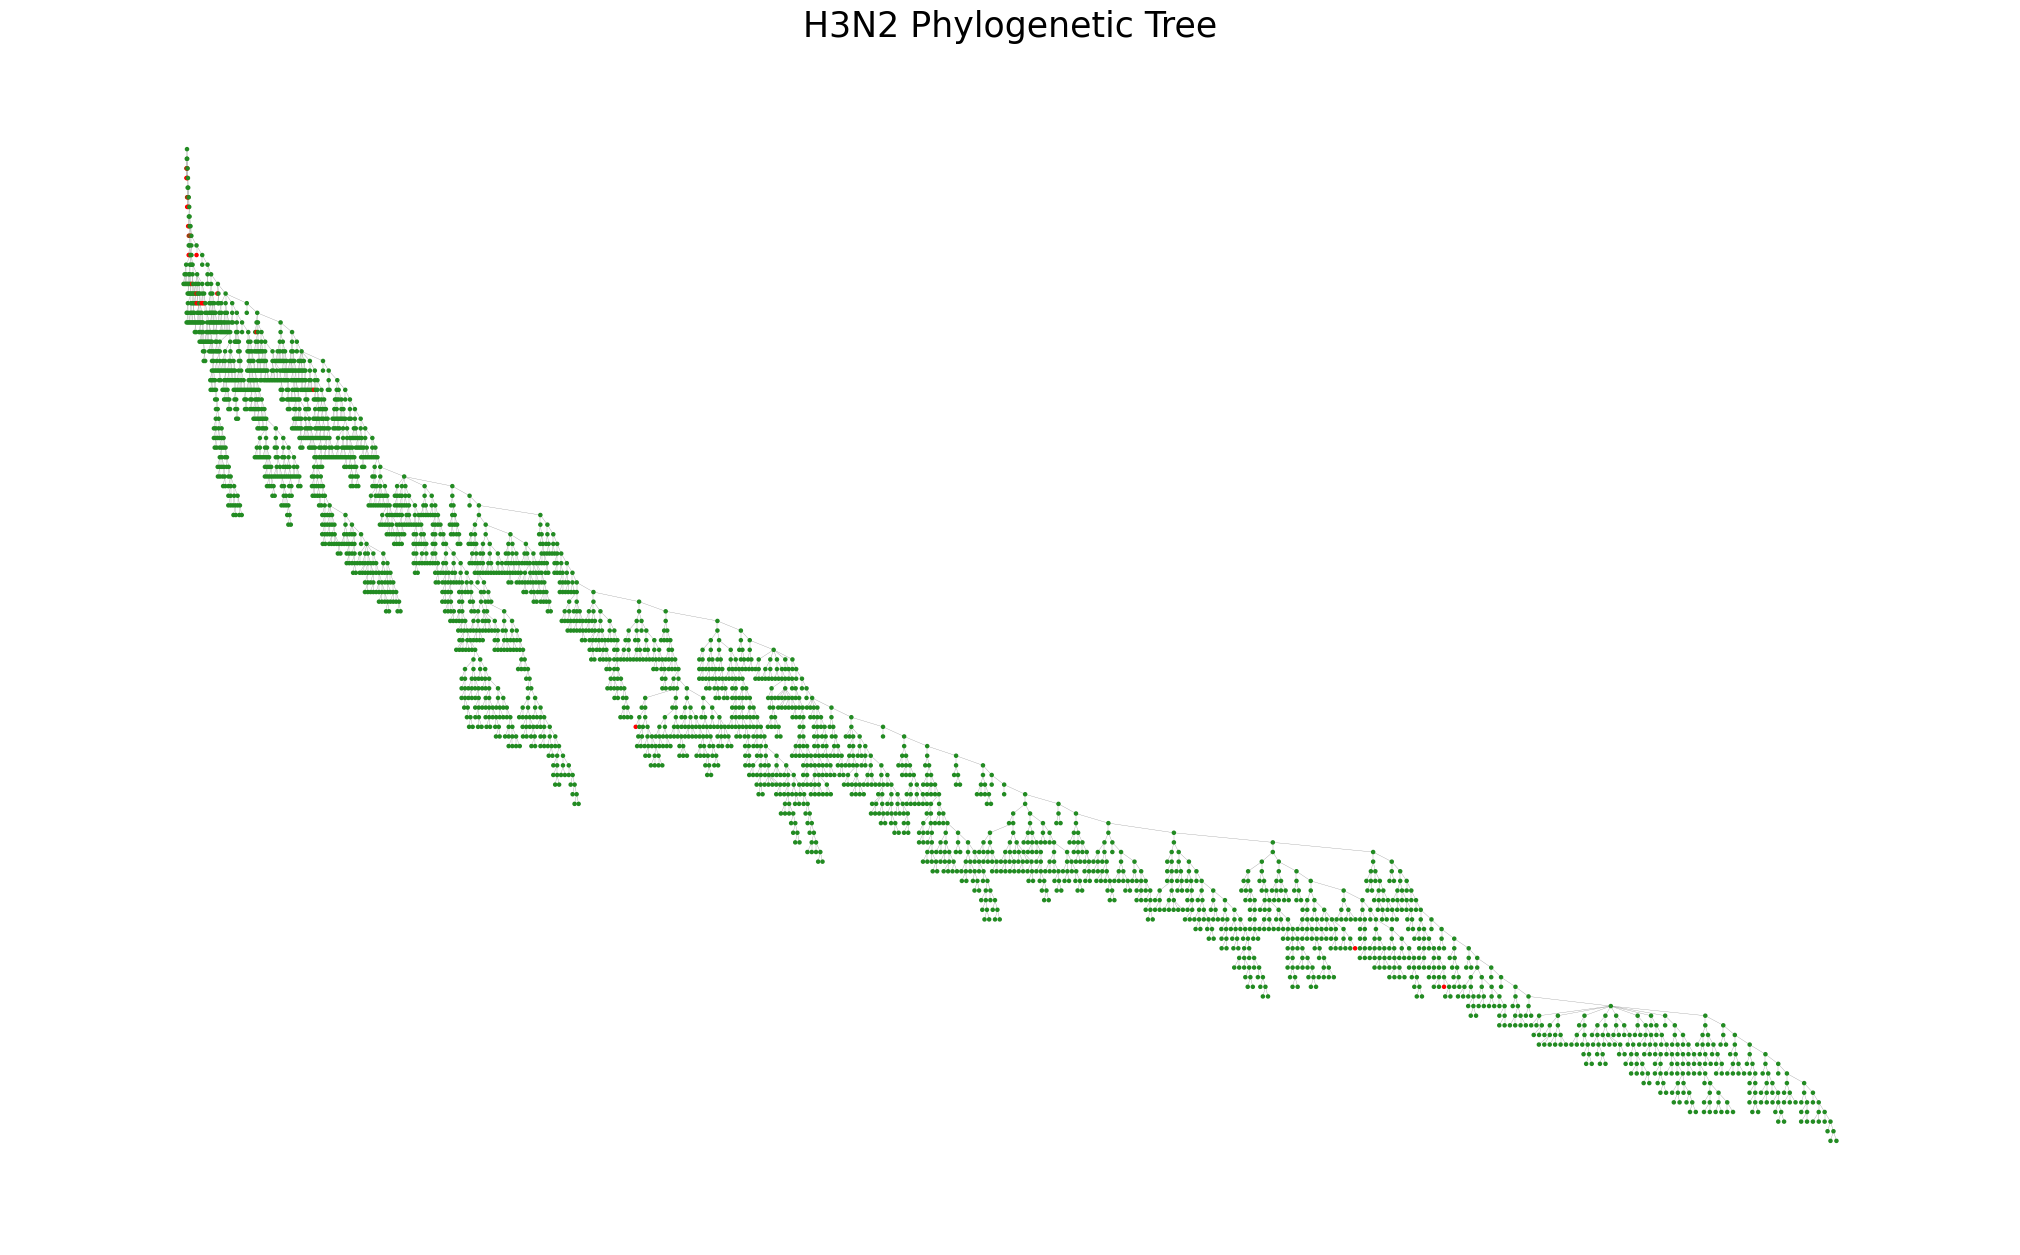

In [3]:
h3n2_phylo_tree = h3n2_test_graph.phylo_tree
nodes_to_prune = h3n2_test_graph._get_nodes_to_prune(h3n2_phylo_tree)

plt.figure(figsize=(20, 12))

pos = nx.nx_agraph.graphviz_layout(h3n2_phylo_tree, prog="dot")

node_colors = [
    "red" if node in nodes_to_prune else "forestgreen"
    for node in h3n2_phylo_tree.nodes()
]

nx.draw(
    h3n2_phylo_tree,
    pos,
    with_labels=False,
    node_size=5,
    node_color=node_colors,
    edge_color="grey",
    width=0.2,
    arrows=False
)

plt.title("H3N2 Phylogenetic Tree", fontsize=25)
plt.show()

Let's see what the pruned trees look like.

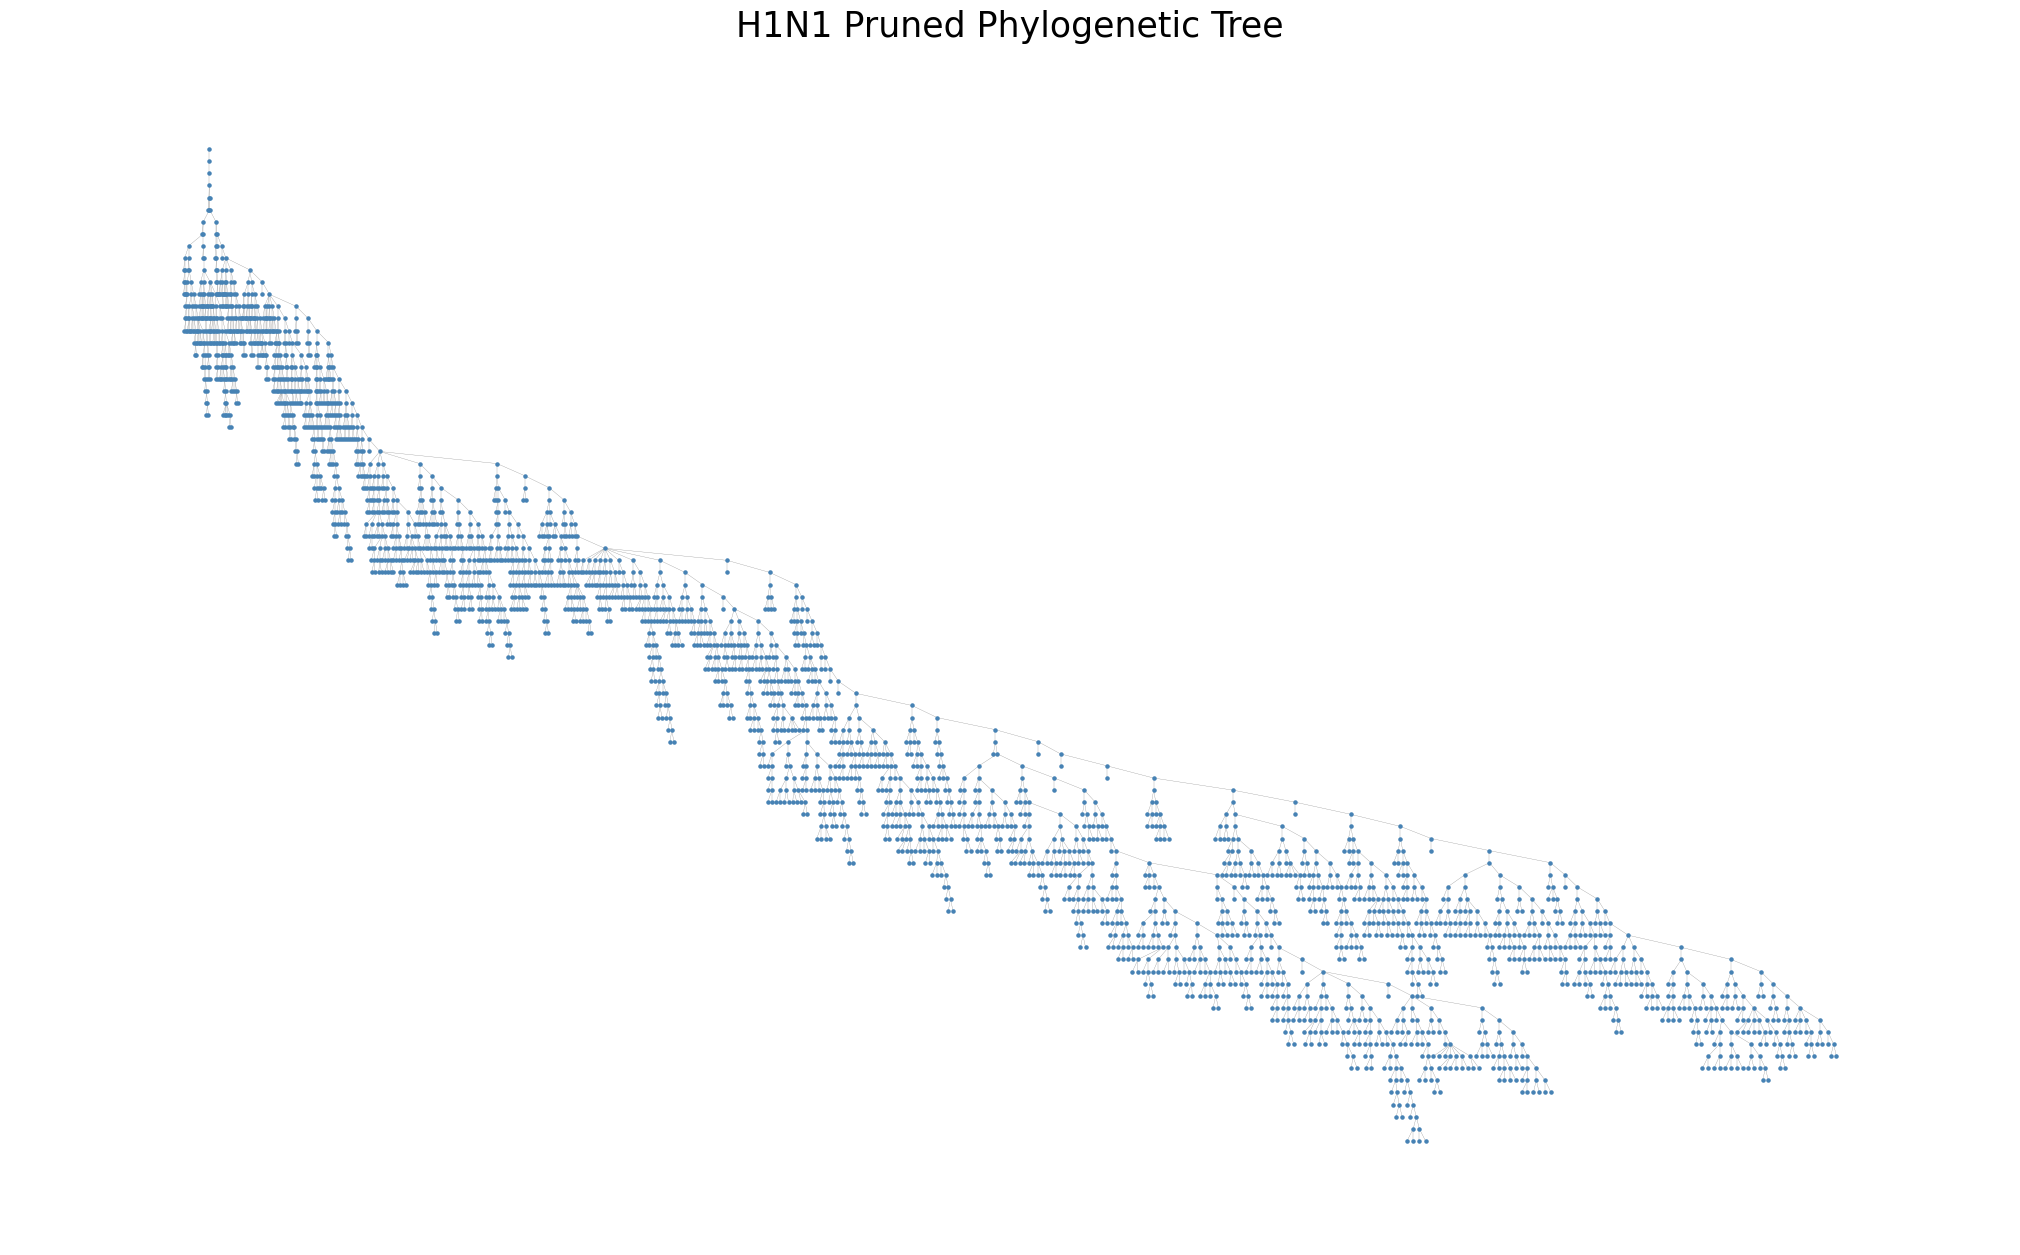

In [4]:
h1n1_phylo_tree_pruned = h1n1_test_graph.pruned_phylo_tree

plt.figure(figsize=(20, 12))

pos = nx.nx_agraph.graphviz_layout(h1n1_phylo_tree_pruned, prog="dot")

nx.draw(
    h1n1_phylo_tree_pruned,
    pos,
    with_labels=False,
    node_size=5,
    node_color='steelblue',
    edge_color="grey",
    width=0.2,
    arrows=False
)

plt.title("H1N1 Pruned Phylogenetic Tree", fontsize=25)
plt.show()

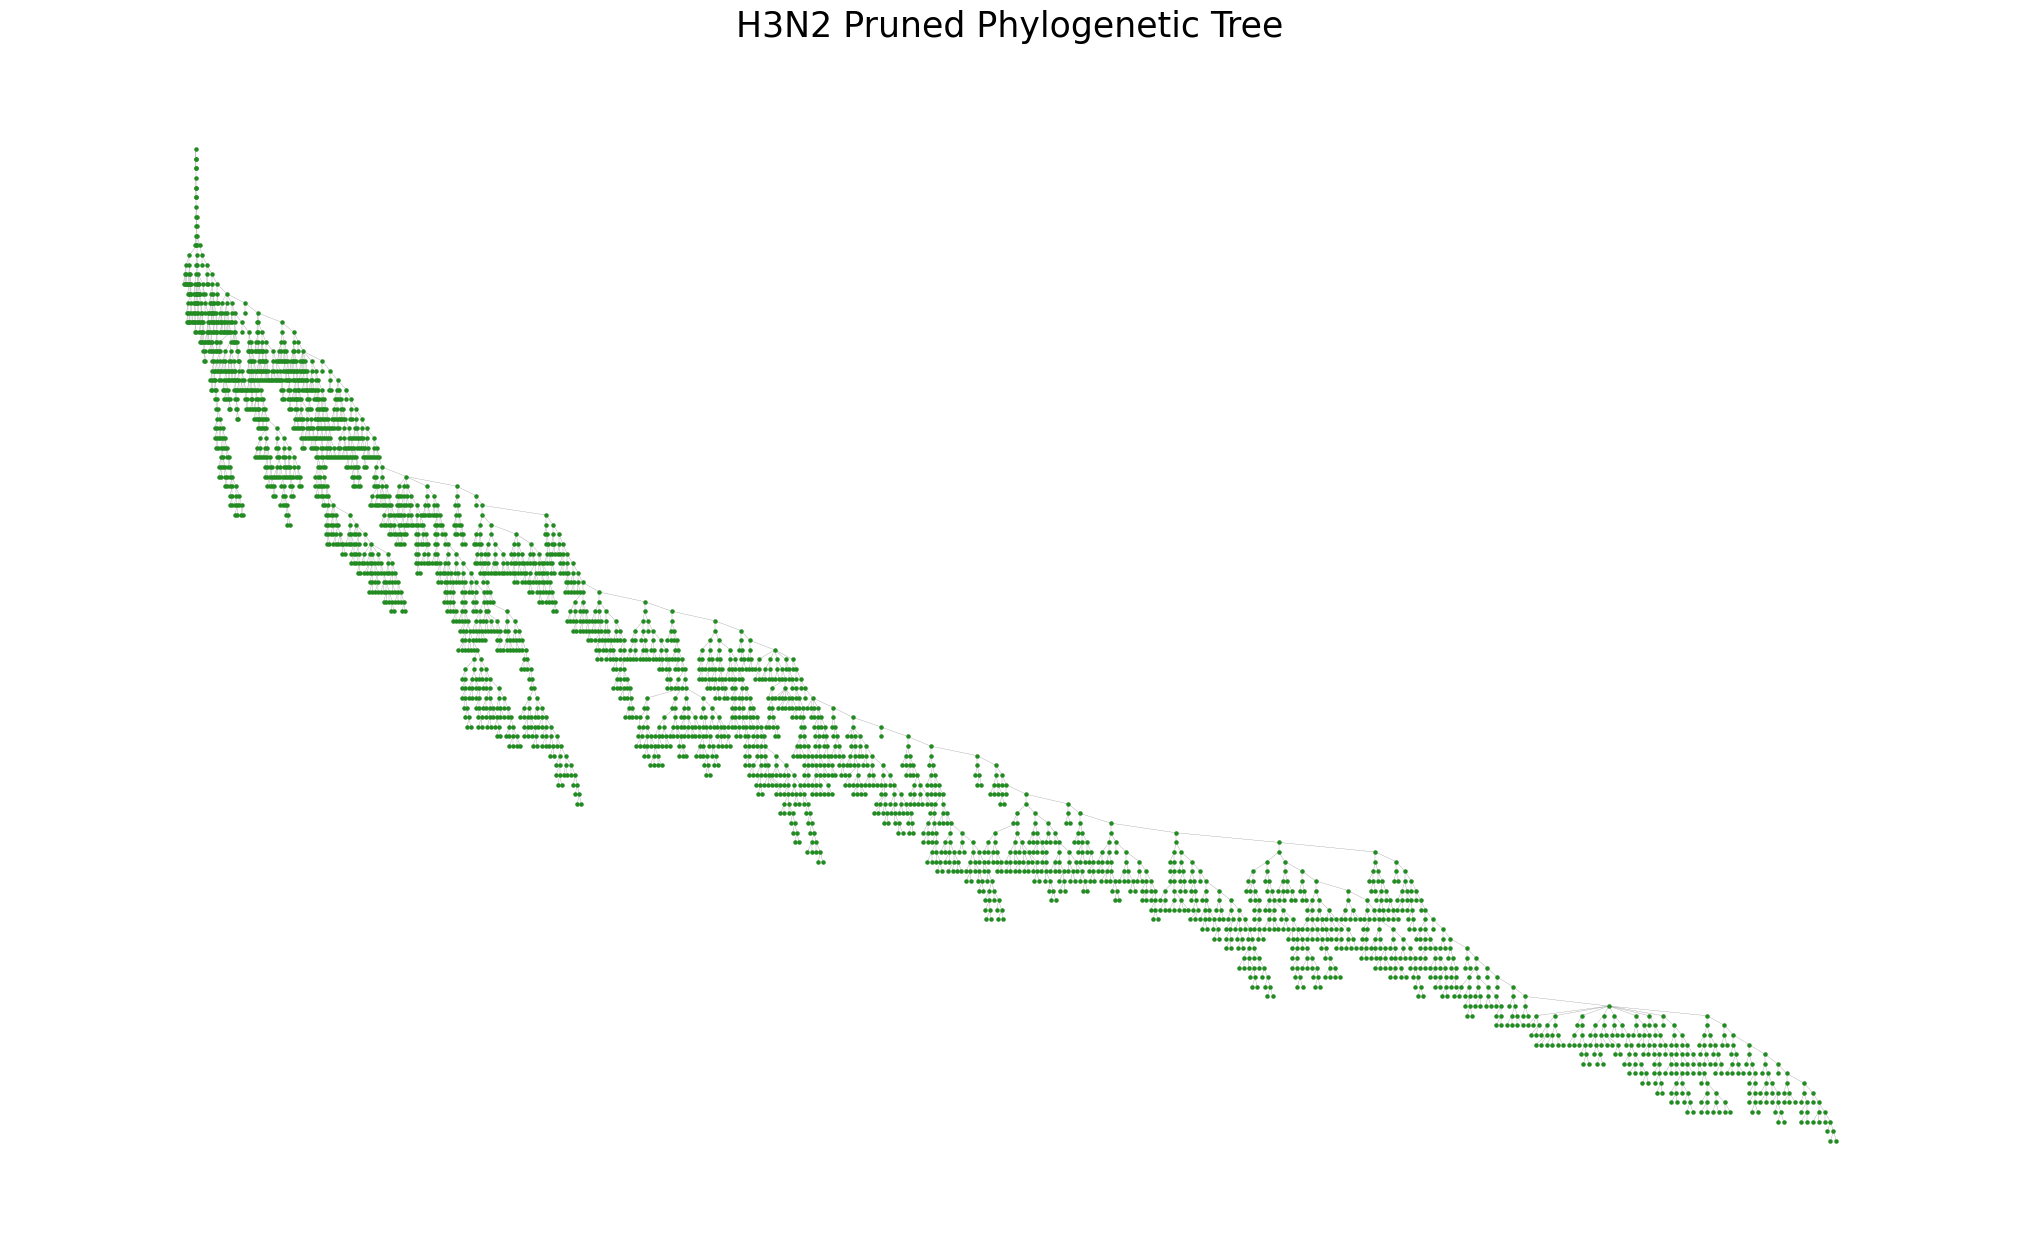

In [5]:
h3n2_phylo_tree_pruned = h3n2_test_graph.pruned_phylo_tree

plt.figure(figsize=(20, 12))

pos = nx.nx_agraph.graphviz_layout(h3n2_phylo_tree_pruned, prog="dot")

nx.draw(
    h3n2_phylo_tree_pruned,
    pos,
    with_labels=False,
    node_size=5,
    node_color='forestgreen',
    edge_color="grey",
    width=0.2,
    arrows=False
)

plt.title("H3N2 Pruned Phylogenetic Tree", fontsize=25)
plt.show()

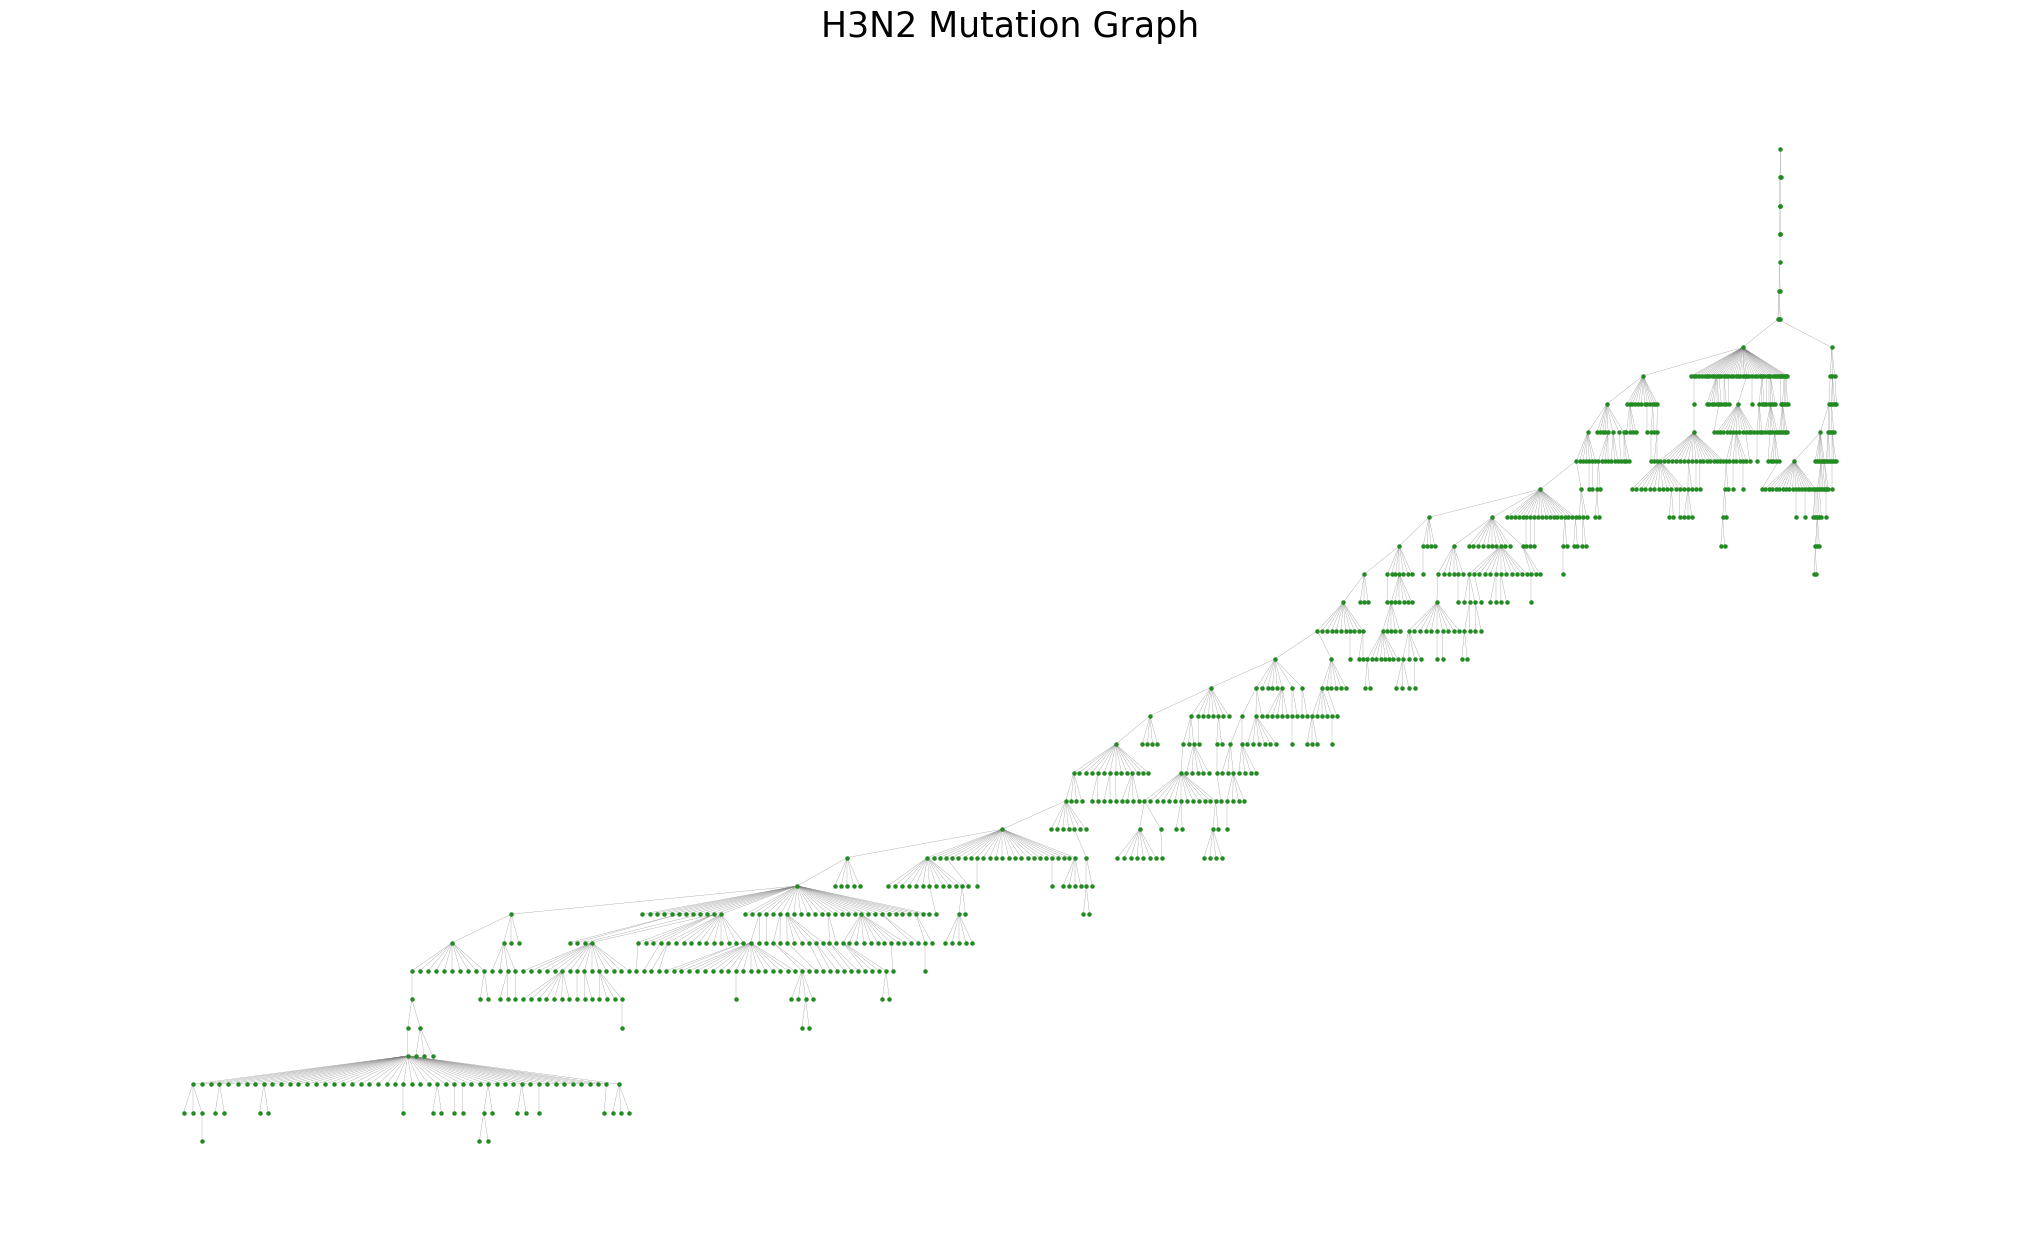

In [20]:
h3n2_mutation_graph = h3n2_test_graph.mutation_graph

plt.figure(figsize=(20, 12))

pos = nx.nx_agraph.graphviz_layout(h3n2_mutation_graph, prog="dot")

nx.draw(
    h3n2_mutation_graph,
    pos,
    with_labels=False,
    node_size=5,
    node_color='forestgreen',
    edge_color="grey",
    width=0.2,
    arrows=False
)

plt.title("H3N2 Mutation Graph", fontsize=25)
plt.show()